# 04 — Model Training (subject-independent)

## Task definition

| Candidate target | Available? | Decision |
|---|---|---|
| Rest vs. multitasking (`lo`/`hi`) | all 96 recordings, balanced, paired | **primary task: binary classification** |
| Self-rated workload 1–9 | one value per recording, 45 subjects | pooled over conditions ≈ the condition label (all 45 subjects rate test > rest) → no new information |
| Test-condition rating between subjects | 45 values, range 4–9 | **secondary task: regression** at recording level (low power, reported honestly) |
| Multiclass from ratings | would need arbitrary cut-offs on an ordinal scale | **not done** — no principled mapping exists in the documentation |

Window-level samples (4 s) are the classifier input; each window inherits its recording's label. Windows of one recording are strongly correlated,
so the effective sample size is closer to 48 subjects than to 5 554 windows — this is why evaluation is grouped by subject and why
confidence intervals are bootstrapped over subjects (Stage 5).

## Cross-validation protocol

* **Outer loop:** `GroupKFold(8, shuffled)` over subjects → each fold tests on 6 unseen subjects (both of their recordings).
* **Inner loop:** `GroupKFold(4)` over the *training* subjects only → hyper-parameter selection by ROC-AUC.
* All learned transforms (median imputation of bad-channel NaNs, standardisation) are pipeline steps, fitted on training folds only.

In [1]:
import sys, json, time
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut

from data_loader import load_ratings, CONDITIONS
from modeling import model_specs, nested_cv, fixed_cv, score_threshold
from evaluation import classification_metrics, recording_level, regression_metrics

OUT = ROOT / "results" / "04_modeling"; OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR = ROOT / "results" / "figures" / "04_modeling"; FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 160, "display.max_columns", 30)

table = pd.read_csv(ROOT / "data" / "features" / "features.csv.gz")
META_COLS = ["subject", "condition", "label", "start_s"]
meta, X = table[META_COLS], table.drop(columns=META_COLS)
y, groups = meta.label.values, meta.subject.values
print("X:", X.shape, "| class balance (test share):", round(y.mean(), 3), "| subjects:", meta.subject.nunique())

X: (5554, 282) | class balance (test share): 0.47 | subjects: 48


## Models

* **Logistic regression** models $P(y=1\mid x)=\sigma(w^\top x+b)$, $\sigma(z)=1/(1+e^{-z})$, minimising log-loss $+\frac{1}{2C}\lVert w\rVert^2$.
  The L2 penalty shrinks the weights of the many collinear features (Stage 3) and is the natural first baseline: linear, convex, interpretable.
* **SVM (RBF)** maximises the margin between classes with hinge loss; the Gaussian kernel $k(x,x')=\exp(-\gamma\lVert x-x'\rVert^2)$ makes the decision
  boundary non-linear. $C$ trades margin width against training errors; $\gamma$ = `scale` = $1/(p\,\mathrm{Var}(X))$.
* **Random forest** averages many deep trees trained on bootstrap samples with random feature subsets ($\sqrt p$ per split), which decorrelates the
  trees and lowers the variance of the average. `min_samples_leaf` controls how finely each tree can fit (larger = smoother).
* **Gradient boosting** builds trees sequentially, each fitting the negative gradient of the log-loss of the current ensemble (a functional
  gradient-descent step of size `learning_rate`). The histogram variant bins features and handles missing values natively.

**Baselines.** (i) *chance*: predicts the training prior (AUC 0.5). (ii) *classic index*: logistic regression on the single feature
`fT_pA` = log(frontal θ / parietal α), the textbook EEG workload index — what a domain-knowledge rule achieves without machine learning on 282 features.

In [2]:
specs = model_specs()
oof, timing = {}, {}
t0 = time.time()
oof["classic_index"] = fixed_cv(make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression()), X[["fT_pA"]], y, groups)
timing["classic_index"] = time.time() - t0
for name, spec in specs.items():
    t0 = time.time()
    oof[name] = nested_cv(spec, X, y, groups, outer_splits=8, inner_splits=4, n_jobs=8)
    timing[name] = time.time() - t0
    m = classification_metrics(y, oof[name].pred, oof[name].score)
    print(f"{name:>14}: window AUC {m['roc_auc']:.3f}, balanced acc {m['balanced_accuracy']:.3f}  ({timing[name]:.0f} s)")

        chance: window AUC 0.472, balanced acc 0.500  (0 s)


        logreg: window AUC 0.881, balanced acc 0.800  (32 s)


       svm_rbf: window AUC 0.877, balanced acc 0.793  (38 s)


 random_forest: window AUC 0.877, balanced acc 0.801  (110 s)


    grad_boost: window AUC 0.863, balanced acc 0.793  (212 s)


## First look at the out-of-fold results

Full evaluation (confidence intervals, confusion matrices, per-subject results, ablations) is in notebook 05. Here we only check that
training worked and inspect the hyper-parameters chosen in each outer fold — stable choices indicate a well-posed tuning problem.

In [3]:
rows = []
for name, o in oof.items():
    thr = 0.5 if name in ("classic_index",) else score_threshold(name)
    w = classification_metrics(y, o.pred, o.score)
    r = recording_level(meta, o, thr)
    rm = classification_metrics(r.label, r.pred, r.score)
    rows.append({"model": name, "win_auc": w["roc_auc"], "win_bal_acc": w["balanced_accuracy"], "win_f1": w["f1"],
                 "rec_auc": rm["roc_auc"], "rec_acc": rm["accuracy"], "train_time_s": timing[name]})
quick = pd.DataFrame(rows).set_index("model")
display(quick.round(3))

params = {n: o.groupby("fold").best_params.first() for n, o in oof.items() if "best_params" in o}
display(pd.DataFrame({n: p.astype(str) for n, p in params.items()}))

,win_auc,win_bal_acc,win_f1,rec_auc,rec_acc,train_time_s
model,,,,,,
classic_index,0.645,0.603,0.553,0.689,0.656,0.044
chance,0.472,0.500,0.000,0.489,0.500,0.061
logreg,0.881,0.800,0.789,0.957,0.865,31.643
svm_rbf,0.877,0.793,0.783,0.958,0.875,38.169
random_forest,0.877,0.801,0.790,0.951,0.885,109.911
grad_boost,0.863,0.793,0.789,0.928,0.865,212.335


,chance,logreg,svm_rbf,random_forest,grad_boost
fold,,,,,
0,{},{'clf__C': 0.01},{'clf__C': 0.1},{'clf__min_samples_leaf': 10},"{'clf__learning_rate': 0.1, 'clf__max_leaf_nod..."
1,{},{'clf__C': 0.01},{'clf__C': 1.0},{'clf__min_samples_leaf': 1},"{'clf__learning_rate': 0.1, 'clf__max_leaf_nod..."
2,{},{'clf__C': 0.01},{'clf__C': 0.1},{'clf__min_samples_leaf': 1},"{'clf__learning_rate': 0.1, 'clf__max_leaf_nod..."
3,{},{'clf__C': 0.01},{'clf__C': 0.1},{'clf__min_samples_leaf': 10},"{'clf__learning_rate': 0.1, 'clf__max_leaf_nod..."
4,{},{'clf__C': 0.01},{'clf__C': 0.1},{'clf__min_samples_leaf': 10},"{'clf__learning_rate': 0.1, 'clf__max_leaf_nod..."
5,{},{'clf__C': 0.001},{'clf__C': 0.1},{'clf__min_samples_leaf': 10},"{'clf__learning_rate': 0.03, 'clf__max_leaf_no..."
6,{},{'clf__C': 0.1},{'clf__C': 1.0},{'clf__min_samples_leaf': 1},"{'clf__learning_rate': 0.1, 'clf__max_leaf_nod..."
7,{},{'clf__C': 0.01},{'clf__C': 1.0},{'clf__min_samples_leaf': 10},"{'clf__learning_rate': 0.1, 'clf__max_leaf_nod..."


## Secondary task: predicting test-condition workload ratings between subjects

Question: among people performing the *same* task, does EEG predict who reports higher workload? One sample per subject (45 rated subjects):
the recording-level mean of each window feature in the test recording. Ridge regression ($\ell_2$-penalised least squares; penalty chosen by
efficient leave-one-out *within* the training subjects, `RidgeCV`) evaluated with **leave-one-subject-out**. Baseline: predicting the training mean.

With $n=45$ and $p=282$ the problem is heavily under-determined; ridge keeps it solvable, but we expect little or no predictive power.
We also check, at no extra training cost, whether the best classifier's out-of-fold recording score for the test recording correlates with the rating.

,mae,rmse,r2,n,spearman_rho
ridge,1.254,1.439,-0.047,45.0,-0.969
mean_baseline,1.253,1.438,-0.046,45.0,NaN


median selected ridge alpha: 100000.0
logreg OOF score of test recordings vs test rating: Spearman rho = 0.17, p = 0.28


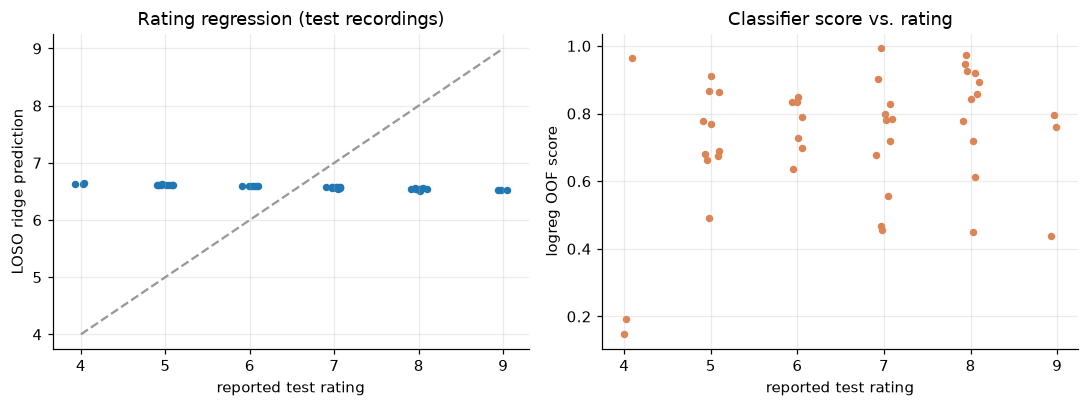

In [4]:
ratings = load_ratings()
rec_feat = table[table.condition == "hi"].groupby("subject")[list(X.columns)].mean()
subs = [s for s in rec_feat.index if s in ratings.index]
Xr, yr = rec_feat.loc[subs], ratings.loc[subs, "rating_test"].values.astype(float)
pred_ridge, pred_mean, alphas = np.zeros(len(yr)), np.zeros(len(yr)), []
for tr, te in LeaveOneOut().split(Xr):
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-1, 5, 25)))
    m.fit(Xr.iloc[tr], yr[tr]); pred_ridge[te] = m.predict(Xr.iloc[te]); alphas.append(m[-1].alpha_)
    pred_mean[te] = yr[tr].mean()
reg = pd.DataFrame({"ridge": regression_metrics(yr, pred_ridge), "mean_baseline": regression_metrics(yr, pred_mean)}).T
reg["spearman_rho"] = [stats.spearmanr(yr, pred_ridge).statistic, np.nan]
display(reg.round(3))
print("median selected ridge alpha:", np.median(alphas))

best_clf = quick.drop(index=["chance", "classic_index"]).win_auc.idxmax()
rl = recording_level(meta, oof[best_clf], score_threshold(best_clf))
rl_hi = rl[rl.condition == "hi"].set_index("subject").loc[subs]
rho = stats.spearmanr(rl_hi.score, yr)
print(f"{best_clf} OOF score of test recordings vs test rating: Spearman rho = {rho.statistic:.2f}, p = {rho.pvalue:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(yr + np.random.default_rng(0).uniform(-.1, .1, len(yr)), pred_ridge, s=15)
axes[0].plot([4, 9], [4, 9], color="0.6", ls="--"); axes[0].set_xlabel("reported test rating"); axes[0].set_ylabel("LOSO ridge prediction")
axes[0].set_title("Rating regression (test recordings)")
axes[1].scatter(yr + np.random.default_rng(1).uniform(-.1, .1, len(yr)), rl_hi.score, s=15, color="#DD8452")
axes[1].set_xlabel("reported test rating"); axes[1].set_ylabel(f"{best_clf} OOF score"); axes[1].set_title("Classifier score vs. rating")
fig.tight_layout(); fig.savefig(FIG_DIR / "rating_regression.png", bbox_inches="tight"); plt.show()

## Save out-of-fold predictions

In [5]:
allp = []
for name, o in oof.items():
    d = meta.join(o[["fold", "score", "pred"]]); d.insert(0, "model", name); allp.append(d)
pd.concat(allp).to_csv(OUT / "oof_predictions.csv.gz", index=False, float_format="%.6g")
pd.DataFrame({"subject": subs, "rating_test": yr, "pred_ridge": pred_ridge, "pred_mean": pred_mean,
              f"{best_clf}_score": rl_hi.score.values}).to_csv(OUT / "rating_regression.csv", index=False)
summary = {"task": "binary rest (0) vs SIMKAP multitasking (1); window-level input, 4 s windows",
           "cv": {"outer": "GroupKFold(8, shuffle=True, random_state=0) over subjects", "inner": "GroupKFold(4) over training subjects, scoring roc_auc"},
           "models": {n: s.description for n, s in specs.items()} | {"classic_index": "logistic regression on log(frontal theta / parietal alpha)"},
           "quick_metrics": quick.round(4).reset_index().to_dict(orient="records"),
           "best_params_per_fold": {n: [str(v) for v in p] for n, p in params.items()},
           "rating_regression": reg.round(4).reset_index().rename(columns={"index": "model"}).to_dict(orient="records"),
           "classifier_score_vs_rating_spearman": {"model": best_clf, "rho": float(rho.statistic), "p": float(rho.pvalue)}}
with open(OUT / "summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved:", *sorted(p.name for p in OUT.iterdir()))

saved: oof_predictions.csv.gz rating_regression.csv summary.json


## Findings

**Classification (rest vs. multitasking, unseen subjects).**

| model | window AUC | window balanced acc. | recording AUC | recording acc. |
|---|---|---|---|---|
| chance (prior) | 0.47* | 0.50 | 0.49 | 0.50 |
| classic index fT/pA (1 feature) | 0.645 | 0.603 | 0.689 | 0.656 |
| logistic regression | **0.881** | 0.800 | 0.957 | 0.865 |
| SVM (RBF) | 0.877 | 0.793 | **0.958** | 0.875 |
| random forest | 0.877 | **0.801** | 0.951 | **0.885** |
| gradient boosting | 0.863 | 0.793 | 0.928 | 0.865 |

\* The prior classifier outputs a constant *within* each fold, but the training prior differs slightly between folds, so the pooled AUC is not exactly 0.5.

- All four learned models clearly beat both baselines and are **within ~0.02 AUC of each other**: L2 logistic regression is as good as the non-linear models.
  With 48 subjects, extra model capacity does not help; the limiting factor is between-subject variability, not model expressiveness.
- Averaging window scores per recording raises discrimination substantially (AUC ≈ 0.95–0.96): window-level noise averages out over ~1 minute of clean data.
- Hyper-parameter choices are stable across outer folds (logistic regression chose C = 0.01 in 6/8 folds — strong regularisation, consistent with
  282 collinear features).
- The single classic workload index achieves only 0.645 AUC: domain-knowledge features alone transfer poorly across individuals.

**Rating regression (secondary).** Ridge on recording-mean features does *not* predict between-subject differences in test ratings: R² = −0.05,
identical to predicting the training mean (MAE 1.25 on a 1–9 scale). The inner LOO always chose the largest penalty (α = 10⁵), i.e. the model collapsed to the mean.
The Spearman ρ = −0.97 between predictions and ratings is a **known leave-one-out artifact**, not a finding: when one subject is left out, the training
mean shifts *away* from that subject's rating, so mean-like predictions are almost perfectly anti-correlated with the truth.
The classifier's out-of-fold test-recording score is also unrelated to the rating (ρ = 0.17, p = 0.28). Conclusion: EEG here separates *states*
(rest vs. task) but gives no evidence of tracking *how much* workload individuals report under the same task — with n = 45 this is underpowered, not proof of absence.

Next (notebook 05): confidence intervals, per-subject analysis, permutation test, feature importance and artifact-confound ablations.
